# Practical 1: results (E1–E6), recommendations, and hardware comparison (Part E)

Figures and tables for report sections 4, 6 and 7. Run top to bottom; figures are saved to `analysis/figures/`.

* **E1–E6** use the fixed code on `luke-mbp16`, the only machine that ran every experiment on the
  fixed code with 5 reps.
* **Part E** uses every member's CORE runs. `indexes/` is identical across the three original-code
  commits (`74dd729`, `a193a9d`, `65a8adf`) and across the three fixed-code commits (`ccf1a10`,
  `fe9f078`, `b204397`), so they are grouped as *original* and *fixed*.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 3)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

df = pd.read_csv("../results/timings.csv")
df["us_per_op"] = df.total_ns / df.n_ops / 1_000
df["code"] = np.where(df.code_version.isin(["ccf1a10", "fe9f078", "b204397"]), "fixed", "original")

E = df[(df.code == "fixed") & (df.machine_id == "luke-mbp16") & df.experiment.str.match(r"E[1-6]_")]

MAIN = ["unsorted_list", "sorted_list", "hash_table", "avl_tree", "bplus_tree"]
REFS = ["ref_dict", "ref_bisect"]
ORDER = MAIN + REFS
COLORS = {i: f"C{k}" for k, i in enumerate(ORDER)}

In [2]:
def iqr_plot(ax, rows, x):
    """Median line with a shaded IQR band (across reps) for each index."""
    q = rows.groupby(["index_type", x]).us_per_op.quantile([0.25, 0.5, 0.75]).unstack()
    for i in ORDER:
        if i not in q.index.get_level_values(0):
            continue
        d = q.loc[i]
        ax.plot(d.index, d[0.5], label=i, color=COLORS[i], ls="--" if i in REFS else "-", marker="o", ms=4)
        ax.fill_between(d.index, d[0.25], d[0.75], color=COLORS[i], alpha=0.2)
    ax.grid(True, which="both", alpha=0.3)

def median_table(rows, x, y="us_per_op"):
    t = rows.pivot_table(index=x, columns="index_type", values=y, aggfunc="median")
    return t[[c for c in ORDER if c in t.columns]]

def loglog_slope(rows, x):
    """Slope of log10(median µs per op) on log10(x), per index."""
    t = median_table(rows, x)
    lx = np.log10(t.index.to_numpy(float))
    return pd.Series({i: np.polyfit(lx, np.log10(t[i]), 1)[0] for i in t.columns}, name="slope")

def crossover(t, a, b):
    """x at which index b becomes cheaper than index a (log-log interpolation), or None."""
    d = np.log(t[a]) - np.log(t[b])
    xs = t.index.to_numpy(float)
    for j in range(1, len(xs)):
        if np.sign(d.iloc[j - 1]) != np.sign(d.iloc[j]):
            f = d.iloc[j - 1] / (d.iloc[j - 1] - d.iloc[j])
            return float(np.exp(np.log(xs[j - 1]) + f * (np.log(xs[j]) - np.log(xs[j - 1]))))
    return None

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=150); plt.show()

## E1: build cost and memory vs *n* (`track_id`, file order)

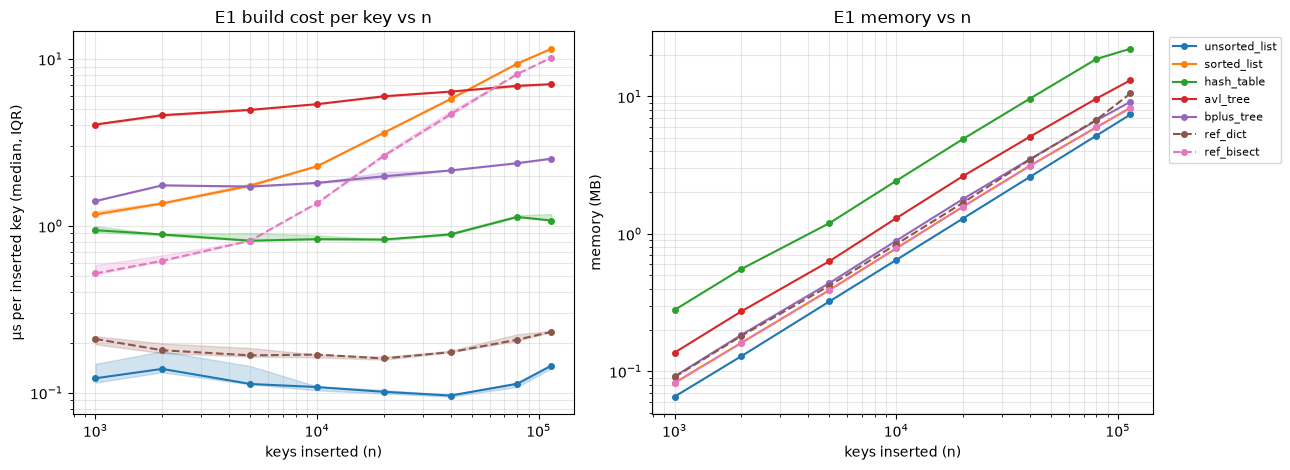

index_type,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
n_keys,,,,,,,
1000,0.122,1.172,0.942,4.046,1.408,0.210,0.519
2000,0.139,1.362,0.888,4.601,1.748,0.180,0.617
5000,0.113,1.742,0.815,4.951,1.719,0.168,0.816
10000,0.108,2.276,0.833,5.359,1.809,0.169,1.369
20000,0.101,3.614,0.829,5.973,1.980,0.161,2.625
40000,0.096,5.752,0.888,6.371,2.147,0.175,4.653
80000,0.113,9.375,1.130,6.896,2.373,0.208,8.118
114000,0.145,11.501,1.077,7.060,2.526,0.232,10.187


,slope of per-key build cost
unsorted_list,-0.01
sorted_list,0.50
hash_table,0.04
avl_tree,0.12
bplus_tree,0.11
ref_dict,0.02
ref_bisect,0.67


,MB,bytes per key
index_type,,
unsorted_list,7.4,64.9
sorted_list,8.3,72.6
hash_table,22.3,195.3
avl_tree,13.1,115.2
bplus_tree,9.2,80.3
ref_dict,10.5,92.3
ref_bisect,8.3,72.6


In [3]:
e1 = E[E.experiment.str.startswith("E1")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
iqr_plot(axes[0], e1, "n_keys")
axes[0].set(xscale="log", yscale="log", xlabel="keys inserted (n)", ylabel="µs per inserted key (median, IQR)",
            title="E1 build cost per key vs n")
mem = median_table(e1, "n_keys", "memory_bytes") / 1e6
for i in ORDER:
    axes[1].plot(mem.index, mem[i], label=i, color=COLORS[i], ls="--" if i in REFS else "-", marker="o", ms=4)
axes[1].set(xscale="log", yscale="log", xlabel="keys inserted (n)", ylabel="memory (MB)", title="E1 memory vs n")
axes[1].grid(True, which="both", alpha=0.3); axes[1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
save(fig, "e1_build_memory.png")

display(median_table(e1, "n_keys").round(3))
display(loglog_slope(e1, "n_keys").round(2).to_frame("slope of per-key build cost"))
display(pd.DataFrame({"MB": mem.iloc[-1], "bytes per key": mem.iloc[-1] * 1e6 / mem.index[-1]}).round(1))

In [4]:
t1 = median_table(e1, "n_keys")
for a, b in [("sorted_list", "bplus_tree"), ("sorted_list", "avl_tree"), ("ref_bisect", "bplus_tree")]:
    print(f"{b} becomes cheaper to build than {a} at n ≈ {crossover(t1, a, b):,.0f}")

bplus_tree becomes cheaper to build than sorted_list at n ≈ 4,775
avl_tree becomes cheaper to build than sorted_list at n ≈ 47,561
bplus_tree becomes cheaper to build than ref_bisect at n ≈ 14,112


**Answer (E1).**
* Per-key build cost is flat for the unsorted list (slope −0.01) and hash table (0.04): O(1).
  AVL (0.12) and B+ tree (0.11) grow slowly: O(log n).
* The sorted list (0.50) and `bisect` (0.67) grow fastest, because each insert shifts every later
  element (O(n) per insert). Their slopes are rising with n; they would be closer to 1 at larger sizes.
* Crossovers: the B+ tree is cheaper to build than the sorted list from n ≈ 4,800, than `bisect` from
  n ≈ 14,000, and the AVL tree is cheaper than the sorted list from n ≈ 48,000.
* Memory at 114k: unsorted list 7.4 MB < sorted list 8.3 < B+ tree 9.2 < `dict` 10.5 < AVL 13.1 < hash table 22.3 MB.

## E2: point lookups vs *n* (`track_id`, hits and misses)

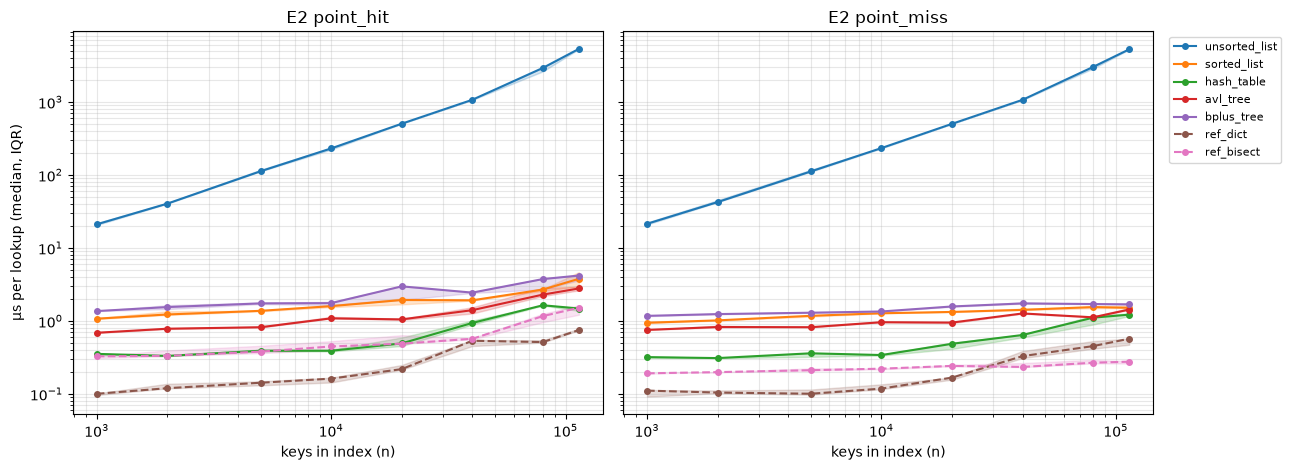

point_hit


index_type,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
n_keys,,,,,,,
1000,21.080,1.074,0.354,0.689,1.366,0.101,0.328
2000,40.486,1.228,0.332,0.783,1.550,0.120,0.333
5000,112.459,1.378,0.391,0.821,1.742,0.143,0.380
10000,231.079,1.597,0.391,1.087,1.756,0.162,0.447
20000,503.788,1.937,0.493,1.051,2.980,0.219,0.489
40000,1071.004,1.919,0.939,1.406,2.446,0.536,0.570
80000,2926.389,2.695,1.641,2.297,3.749,0.514,1.165
114000,5336.651,3.783,1.482,2.789,4.190,0.751,1.518


,point_hit slope
unsorted_list,1.15
sorted_list,0.23
hash_table,0.35
avl_tree,0.28
bplus_tree,0.23
ref_dict,0.43
ref_bisect,0.30


point_miss


index_type,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
n_keys,,,,,,,
1000,21.438,0.945,0.320,0.754,1.175,0.111,0.192
2000,42.514,1.019,0.310,0.826,1.242,0.105,0.199
5000,111.849,1.178,0.361,0.822,1.298,0.101,0.212
10000,233.533,1.275,0.342,0.962,1.349,0.118,0.222
20000,501.666,1.330,0.487,0.951,1.580,0.168,0.242
40000,1070.333,1.419,0.643,1.268,1.739,0.330,0.235
80000,3021.023,1.552,1.110,1.122,1.707,0.453,0.268
114000,5258.558,1.515,1.221,1.434,1.688,0.571,0.277


,point_miss slope
unsorted_list,1.15
sorted_list,0.10
hash_table,0.30
avl_tree,0.12
bplus_tree,0.09
ref_dict,0.38
ref_bisect,0.08


In [5]:
e2 = E[E.experiment.str.startswith("E2")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, op in zip(axes, ["point_hit", "point_miss"]):
    iqr_plot(ax, e2[e2.operation == op], "n_keys")
    ax.set(xscale="log", yscale="log", xlabel="keys in index (n)", title=f"E2 {op}")
axes[0].set_ylabel("µs per lookup (median, IQR)")
axes[1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
save(fig, "e2_point_lookups.png")

for op in ["point_hit", "point_miss"]:
    r = e2[e2.operation == op]
    print(op); display(median_table(r, "n_keys").round(3))
    display(loglog_slope(r, "n_keys").round(2).to_frame(f"{op} slope"))

**Answer (E2).**
* Unsorted list slope 1.15: O(n), as expected.
* Sorted list, AVL and B+ tree slopes are 0.23–0.28 for hits and 0.09–0.12 for misses. They grow
  slowly, consistent with O(log n), though hits grow faster than log n alone would predict.
* The hash table should be flat (O(1)) but has a slope of 0.30–0.35. `dict` shows the same pattern.
* At 114k the hash table is fastest of the five candidates (1.48 µs per hit), then AVL (2.79), sorted
  list (3.78) and B+ tree (4.19).

## E3: range queries vs selectivity (`tempo`, all rows)

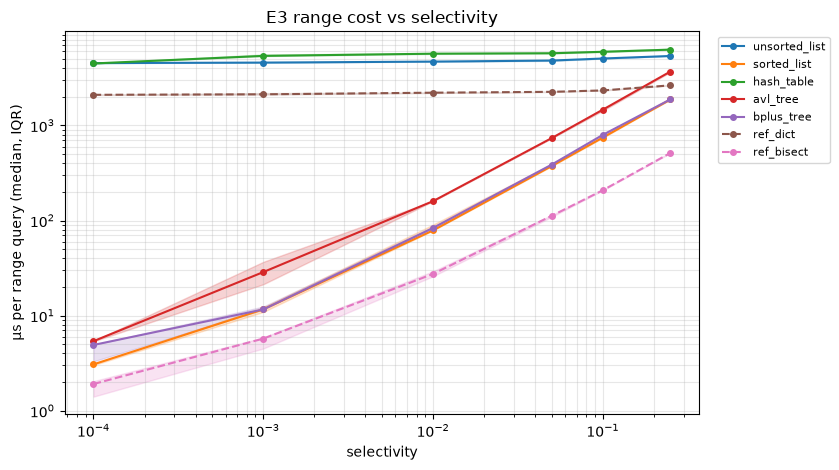

index_type,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
operation_param,,,,,,,
1.000e-04,4523.3,3.1,4480.8,5.4,4.9,2098.3,1.9
1.000e-03,4576.9,11.6,5382.0,28.7,11.6,2123.6,5.7
1.000e-02,4688.2,78.7,5678.5,159.9,83.5,2208.7,27.4
5.000e-02,4808.9,374.0,5735.0,736.2,387.3,2255.0,112.2
1.000e-01,5052.9,745.0,5947.0,1465.4,796.5,2333.2,208.2
2.500e-01,5371.3,1876.0,6263.4,3687.2,1880.9,2638.2,513.6


In [6]:
e3 = E[E.experiment.str.startswith("E3")]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
iqr_plot(ax, e3, "operation_param")
ax.set(xscale="log", yscale="log", xlabel="selectivity", ylabel="µs per range query (median, IQR)",
       title="E3 range cost vs selectivity")
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
save(fig, "e3_range.png")
display(median_table(e3, "operation_param").round(1))

**Answer (E3).**
* The unsorted list and hash table scan every key, so cost is flat (≈4.5–6.3 ms) at every selectivity.
  The hash table is slower than no index at all, because it can't use key order.
* The ordered indexes are O(log n + k): cost grows with the number of rows returned.
* Sorted list and B+ tree are tied (79 vs 84 µs at 0.01; 1,876 vs 1,881 µs at 0.25). AVL is ≈2× slower.

## E4: prefix search vs prefix length (`track_name`)

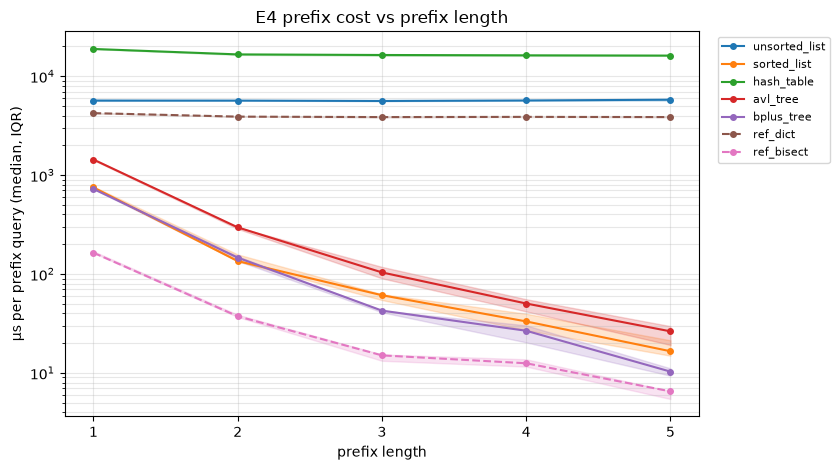

index_type,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
operation_param,,,,,,,
1.0,5673.9,750.8,18872.7,1437.0,724.5,4236.1,164.1
2.0,5669.2,135.2,16625.3,296.5,146.5,3904.7,37.4
3.0,5621.3,61.1,16399.0,103.8,42.7,3862.2,15.1
4.0,5686.9,33.2,16271.6,50.3,26.7,3881.8,12.5
5.0,5791.9,16.6,16169.8,26.3,10.3,3863.8,6.5


In [7]:
e4 = E[E.experiment.str.startswith("E4")]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
iqr_plot(ax, e4, "operation_param")
ax.set(yscale="log", xlabel="prefix length", ylabel="µs per prefix query (median, IQR)",
       title="E4 prefix cost vs prefix length", xticks=[1, 2, 3, 4, 5])
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
save(fig, "e4_prefix.png")
display(median_table(e4, "operation_param").round(1))

**Answer (E4).**
* For the ordered indexes, cost drops sharply as the prefix gets longer, because fewer titles match.
  B+ tree: 725 µs (1 character) → 43 µs (3) → 10 µs (5).
* The B+ tree and sorted list are effectively tied. AVL is ≈2× slower.
* The hash table can't do prefix search except by scanning everything: 16–19 ms, slower than the unsorted list.

## E5: does arrival order matter? (synthetic keys)

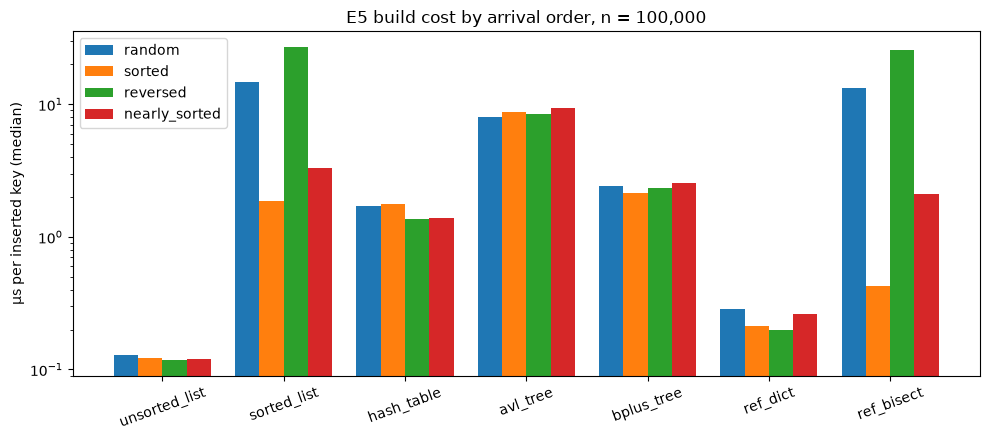

Build µs per key, n = 100,000:


insert_order,random,sorted,reversed,nearly_sorted
index_type,,,,
unsorted_list,0.129,0.122,0.117,0.121
sorted_list,14.646,1.855,27.044,3.319
hash_table,1.705,1.759,1.367,1.377
avl_tree,7.980,8.779,8.425,9.415
bplus_tree,2.426,2.132,2.335,2.549
ref_dict,0.284,0.213,0.198,0.261
ref_bisect,13.347,0.429,25.730,2.089


Lookup µs per hit, n = 100,000:


insert_order,random,sorted,reversed,nearly_sorted
index_type,,,,
unsorted_list,3348.580,3276.406,3296.482,3277.825
sorted_list,2.225,2.153,2.274,2.183
hash_table,1.454,1.628,1.010,0.987
avl_tree,1.952,1.806,1.581,1.754
bplus_tree,2.478,2.357,2.316,2.791
ref_dict,0.406,0.351,0.274,0.333
ref_bisect,0.639,0.770,0.596,0.948


Height, rotations and splits:


height  rotations  splits
index_type n_keys insert_order                            
avl_tree   1000   nearly_sorted    12.0     1144.0     0.0
                  random           12.0      679.0     0.0
                  reversed         10.0      990.0     0.0
                  sorted           10.0      990.0     0.0
           10000  nearly_sorted    16.0    12034.0     0.0
                  random           16.0     7036.0     0.0
                  reversed         14.0     9986.0     0.0
                  sorted           14.0     9986.0     0.0
           100000 nearly_sorted    20.0   120055.0     0.0
                  random           20.0    69760.0     0.0
                  reversed         17.0    99983.0     0.0
                  sorted           17.0    99983.0     0.0
bplus_tree 1000   nearly_sorted     3.0        0.0    59.0
                  random            3.0        0.0    44.0
                  reversed          3.0        0.0    63.0
                  sorted            3.0        0.0    63.0
           10000  nearly_sorted     4.0        0.0   613.0
                  random            3.0        0.0   480.0
                  reversed          4.0        0.0   663.0
                  sorted            4.0        0.0   660.0
           100000 nearly_sorted     4.0        0.0  6135.0
                  random            4.0        0.0  4801.0
                  reversed          4.0        0.0  6661.0
                  sorted            4.0        0.0  6635.0

In [8]:
e5 = E[E.experiment.str.startswith("E5")]
b5 = e5[e5.operation == "build"]
orders = ["random", "sorted", "reversed", "nearly_sorted"]
t5 = (b5[b5.n_keys == b5.n_keys.max()]
      .pivot_table(index="index_type", columns="insert_order", values="us_per_op", aggfunc="median")
      .reindex(ORDER)[orders])

fig, ax = plt.subplots(figsize=(10, 4.5))
for k, o in enumerate(orders):
    ax.bar(np.arange(len(ORDER)) + (k - 1.5) * 0.2, t5[o], 0.2, label=o)
ax.set_xticks(np.arange(len(ORDER)), ORDER, rotation=20)
ax.set(yscale="log", ylabel="µs per inserted key (median)", title=f"E5 build cost by arrival order, n = {b5.n_keys.max():,}")
ax.legend()
save(fig, "e5_build_by_order.png")

print("Build µs per key, n = 100,000:"); display(t5.round(3))
print("Lookup µs per hit, n = 100,000:")
h = e5[(e5.operation == "point_hit") & (e5.n_keys == e5.n_keys.max())]
display(h.pivot_table(index="index_type", columns="insert_order", values="us_per_op", aggfunc="median").reindex(ORDER)[orders].round(3))
print("Height, rotations and splits:")
display(b5[b5.index_type.isin(["avl_tree", "bplus_tree"])]
        .groupby(["index_type", "n_keys", "insert_order"])[["height", "rotations", "splits"]].median())

**Answer (E5).** Order matters mainly for the sorted list and `bisect`.
* At 100k keys, sorted input builds a sorted list at 0.13× the cost of random input (every insert is
  an append). Reversed input costs 1.85× (every insert goes to the front).
* AVL: build time is within 6–18% of random. Sorted input causes 1 rotation per key vs 0.70 for random,
  but gives a shorter tree (height 17 vs 20).
* B+ tree: build within 0.88–1.05× of random; sorted input causes more splits. Height is 4 for every order.
* Hash table and unsorted list are not affected. Lookup times are about the same for every order.

## E6: B+ tree order

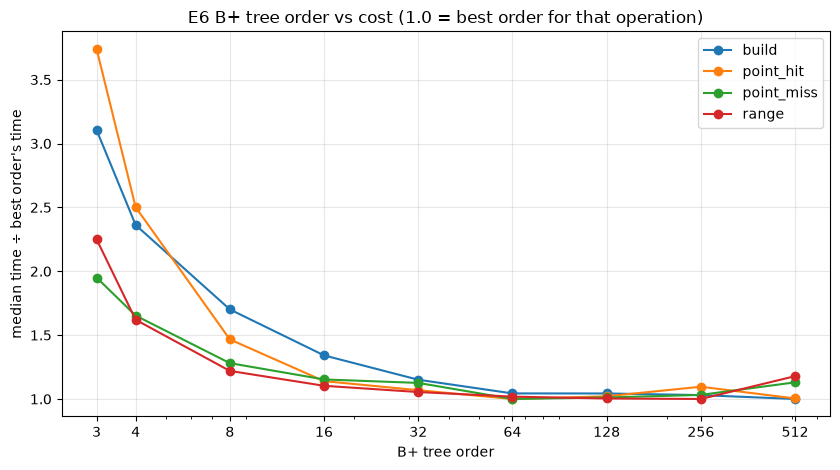

operation,build,point_hit,point_miss,range,height
order,,,,,
3,6.648,9.990,3.006,184.075,14.0
4,5.055,6.680,2.547,132.531,11.0
8,3.641,3.916,1.974,99.769,7.0
16,2.870,3.044,1.777,90.238,5.0
32,2.463,2.854,1.735,86.236,4.0
64,2.233,2.670,1.541,83.294,3.0
128,2.232,2.727,1.559,82.111,3.0
256,2.205,2.927,1.590,81.788,3.0
512,2.140,2.681,1.742,96.402,2.0


In [9]:
e6 = E[E.experiment.str.startswith("E6")].copy()
e6["order"] = e6.index_param.str.replace("order=", "").astype(int)
t6 = e6.pivot_table(index="order", columns="operation", values="us_per_op", aggfunc="median")
t6["height"] = e6[e6.operation == "build"].groupby("order").height.median()

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for op in ["build", "point_hit", "point_miss", "range"]:
    ax.plot(t6.index, t6[op] / t6[op].min(), marker="o", label=op)
ax.set(xscale="log", xlabel="B+ tree order", ylabel="median time ÷ best order's time",
       title="E6 B+ tree order vs cost (1.0 = best order for that operation)")
ax.set_xticks(t6.index, t6.index); ax.grid(True, alpha=0.3); ax.legend()
save(fig, "e6_bplus_order.png")
display(t6.round(3))

**Answer (E6).**
* Small orders are slow: order 3 is 3× slower to build than order 64 and 3.7× slower for point hits.
* The best order is 64 (point lookups), 256 (ranges) or 512 (build), but 64 and 128 are within 5% of
  the best for every operation, so the answer barely depends on the operation.
* Order 512 is worse for ranges (+18% over 256). **Recommendation: order 64 or 128.**

## Is the B+ tree "the answer for everything"? and recommendations

In [10]:
n = E.n_keys.max()
cost = pd.DataFrame({
    "F1 point lookup, hits+misses (E2)": e2[e2.n_keys == n].groupby("index_type").us_per_op.median(),
    "F2 prefix, length 3 (E4)": e4[e4.operation_param == 3].groupby("index_type").us_per_op.median(),
    "F3 range, selectivity 0.01 (E3)": e3[e3.operation_param == 0.01].groupby("index_type").us_per_op.median(),
    "F4 build per key (E1)": e1[e1.n_keys == n].groupby("index_type").us_per_op.median(),
}).T[ORDER]
print("Median µs per operation at full size:"); display(cost.round(2))
print("Rank among the five candidates:"); display(cost[MAIN].rank(axis=1).astype(int))
print("Python ÷ C reference:")
display(pd.DataFrame({"hash_table ÷ ref_dict": cost.hash_table / cost.ref_dict,
                      "sorted_list ÷ ref_bisect": cost.sorted_list / cost.ref_bisect}).round(2))

Median µs per operation at full size:


index_type,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
"F1 point lookup, hits+misses (E2)",5302.25,2.06,1.32,1.77,2.21,0.69,0.60
"F2 prefix, length 3 (E4)",5621.32,61.05,16398.95,103.83,42.68,3862.22,15.05
"F3 range, selectivity 0.01 (E3)",4688.19,78.72,5678.52,159.87,83.54,2208.72,27.44
F4 build per key (E1),0.15,11.50,1.08,7.06,2.53,0.23,10.19


Rank among the five candidates:


index_type,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree
"F1 point lookup, hits+misses (E2)",5,3,1,2,4
"F2 prefix, length 3 (E4)",4,2,5,3,1
"F3 range, selectivity 0.01 (E3)",4,1,5,3,2
F4 build per key (E1),1,5,2,4,3


Python ÷ C reference:


,hash_table ÷ ref_dict,sorted_list ÷ ref_bisect
"F1 point lookup, hits+misses (E2)",1.91,3.46
"F2 prefix, length 3 (E4)",4.25,4.06
"F3 range, selectivity 0.01 (E3)",2.57,2.87
F4 build per key (E1),4.64,1.13


**Is the B+ tree the answer for everything? No.** It is the best, or tied best, for prefix (F2) and
range (F3) queries. But it ranks 4th of 5 for point lookups (1.7× slower than the hash table), and its
build cost is 2.3× the hash table's.

| Feature | Recommend | Runner-up | Evidence (114k rows) | Trade-offs |
|---|---|---|---|---|
| F1 track page | Hash table | AVL tree | 1.32 µs per lookup vs 1.77 (AVL), 2.21 (B+) | Most memory; no range or prefix queries |
| F2 search-as-you-type | B+ tree (order 64–128) | Sorted list | 43 vs 61 µs at prefix length 3 | Hash table can't do prefixes |
| F3 workout mode | B+ tree (order 64–128) | Sorted list | 84 vs 79 µs at selectivity 0.01 (tied) | Sorted list is 4.5× slower to build/update (E1) |
| F4 catalog import | Keep inserts cheap: hash table / B+ tree | n/a | 1.08 and 2.53 µs per key, unaffected by arrival order (E5) | Sorted list costs 11.5 µs per key and grows with n, unless the data arrives sorted |

**Reference indexes.** The C versions are 2–5× faster than the same idea in Python (hash table ÷ `dict`
1.9× for lookups, 4.6× for builds; sorted list ÷ `bisect` 2.9–4.1× for queries). That's a constant factor.
The big-O stays the same: `bisect` still has O(n) inserts, and the Python B+ tree builds faster than it
from ≈14k keys.

# Part E: hardware comparison (CORE suite)

In [11]:
display(pd.read_csv("../machines.csv").set_index("machine_id"))
core = df[df.experiment == "CORE"].copy()
core["workload"] = core.operation + np.where(core.operation == "build", " n=" + core.n_keys.astype(str), "")
fx = core[core.code == "fixed"]

,member,computer_model,cpu_model,cpu_cores,ram_gb,os,docker_cpus,docker_memory_gb,power
machine_id,,,,,,,,,
hugo-mbp,hugo,"MacBook Pro 14"" 2023",Apple M2 Pro,10,16,macOS 15.6.1,10,8.0,plugged in
ray-pc,ray,Dell Inc. Inspiron 16 5640,Intel(R) Core(TM) 7 150U,10,32,Microsoft Windows 11 Pro 10.0.26200,12,15.5,plugged in
luke-mbp16,luke,MacBook Pro 16-inch 2023,Apple M2 Pro,12,16,macOS 26.5.2,12,8.0,plugged in


### Q1. Are the counters identical across machines?

In [12]:
cols = ["comparisons", "nodes_visited", "rotations", "splits", "resizes"]
for c in ["original", "fixed"]:
    d = core[(core.code == c) & core.comparisons.notna()].groupby(["index_type", "workload"])[cols].nunique()
    print(f"{c} code: {(d > 1).any(axis=1).sum()} of {len(d)} configurations have a counter that differs")

original code: 0 of 30 configurations have a counter that differs
fixed code: 0 of 30 configurations have a counter that differs


**Answer (Q1).** Yes. No counter differs across machines or reps in any of the 30 configurations,
before or after the fixes. The CORE suite uses fixed seeds, every run had `PYTHONHASHSEED=0`, and the
index code was the same, so every machine did exactly the same work. (The `dict`/`bisect` references
don't record counters.)

### Q2. How much faster is the fastest machine than the slowest?

In [13]:
med = fx.pivot_table(index=["index_type", "workload"], columns="machine_id", values="us_per_op", aggfunc="median")
mach = list(med.columns)
med["slowest ÷ fastest"] = med[mach].max(axis=1) / med[mach].min(axis=1)
display(med.round(3))
print(med["slowest ÷ fastest"].describe().round(2).to_string())
print("\nFastest:", med[mach].idxmin(axis=1).value_counts().to_dict(), "  Slowest:", med[mach].idxmax(axis=1).value_counts().to_dict())
print("\nMedian ratio by index:"); print(med.groupby(level="index_type")["slowest ÷ fastest"].median().sort_values().round(2).to_string())

machine_id                     hugo-mbp  luke-mbp16     ray-pc  \
index_type    workload                                           
avl_tree      build n=10000       4.959       5.645      6.502   
              build n=114000      6.554       7.091      9.770   
              point_hit           1.932       2.204      4.922   
              point_miss          1.108       1.532      1.988   
              prefix             71.432      79.150    151.126   
              range             153.149     162.330    336.719   
bplus_tree    build n=10000       1.704       1.868      3.639   
              build n=114000      2.389       2.533      4.936   
              point_hit           3.541       2.951      6.406   
              point_miss          1.827       1.923      3.916   
              prefix             36.372      38.082     83.048   
              range              75.748      79.985    211.469   
hash_table    build n=10000       0.770       0.960      0.869   
              build n=114000      0.955       1.089      1.230   
              point_hit           1.106       1.663      1.306   
              point_miss          0.711       1.211      0.883   
              prefix          13134.328   15309.552  30121.846   
              range            3540.230    3628.237   5987.423   
ref_bisect    build n=10000       1.276       1.423      1.074   
              build n=114000      9.405       9.725      5.825   
              point_hit           0.949       0.972      1.265   
              point_miss          0.334       0.402      0.614   
              prefix             10.004       9.808     13.348   
              range              20.946      21.370     31.228   
ref_dict      build n=10000       0.150       0.196      0.249   
              build n=114000      0.208       0.234      0.315   
              point_hit           0.371       0.464      0.535   
              point_miss          0.257       0.344      0.312   
              prefix           3076.051    3320.349   5691.815   
              range            1404.876    1804.419   1909.593   
sorted_list   build n=10000       2.253       2.364      1.667   
              build n=114000     10.653      11.763      6.651   
              point_hit           2.387       2.852      4.100   
              point_miss          1.440       1.897      2.416   
              prefix             37.746      31.649     34.805   
              range              64.930      63.529    107.787   
unsorted_list build n=10000       0.109       0.106      0.174   
              build n=114000      0.089       0.110      0.157   
              point_hit        3604.942    4713.256   5499.467   
              point_miss       3598.560    4699.862   5216.023   
              prefix           4357.101    4417.629   9903.978   
              range            2950.658    3342.092   4878.820   

machine_id                    slowest ÷ fastest  
index_type    workload                           
avl_tree      build n=10000               1.311  
              build n=114000              1.491  
              point_hit                   2.548  
              point_miss                  1.795  
              prefix                      2.116  
              range                       2.199  
bplus_tree    build n=10000               2.135  
              build n=114000              2.066  
              point_hit                   2.171  
              point_miss                  2.144  
              prefix                      2.283  
              range                       2.792  
hash_table    build n=10000               1.246  
              build n=114000              1.289  
              point_hit                   1.503  
              point_miss                  1.705  
              prefix                      2.293  
              range                       1.691  
ref_bisect    build n=10000               1.325  
              build n=114000              1.6

count    42.00
mean      1.73
std       0.38
min       1.19
25%       1.44
50%       1.67
75%       2.01
max       2.79

Fastest: {'hugo-mbp': 33, 'luke-mbp16': 5, 'ray-pc': 4}   Slowest: {'ray-pc': 33, 'luke-mbp16': 8, 'hugo-mbp': 1}

Median ratio by index:
index_type
ref_bisect       1.43
ref_dict         1.48
hash_table       1.60
unsorted_list    1.65
sorted_list      1.69
avl_tree         1.96
bplus_tree       2.16


**Answer (Q2).** On the fixed-code runs, the slowest machine takes a median 1.67× as long as the
fastest (range 1.19–2.79×). hugo-mbp is fastest in 33 of 42 cells and ray-pc slowest in 33.
The ratio is not the same everywhere: it is largest for the B+ tree (2.16) and AVL tree (1.96), and
smallest for the C references (`bisect` 1.43, `dict` 1.48). ray-pc is actually the fastest machine for
sorted-list and `bisect` builds. Ray's fixed-code session was unusually noisy (Q4), so his ratios
should be treated with caution.

### Q3. Does the ranking change between machines?

In [14]:
for w, g in fx.groupby("workload"):
    r = g.pivot_table(index="machine_id", columns="index_type", values="us_per_op", aggfunc="median")[ORDER].rank(axis=1).astype(int)
    print(w); display(r)

build n=10000


index_type,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
machine_id,,,,,,,
hugo-mbp,1,6,3,7,5,2,4
luke-mbp16,1,6,3,7,5,2,4
ray-pc,1,5,3,7,6,2,4


build n=114000


index_type,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
machine_id,,,,,,,
hugo-mbp,1,7,3,5,4,2,6
luke-mbp16,1,7,3,5,4,2,6
ray-pc,1,6,3,7,4,2,5


point_hit


index_type,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
machine_id,,,,,,,
hugo-mbp,7,5,3,4,6,1,2
luke-mbp16,7,5,3,4,6,1,2
ray-pc,7,4,3,5,6,1,2


... (2 outputs left out)

prefix


index_type,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
machine_id,,,,,,,
hugo-mbp,6,3,7,4,2,5,1
luke-mbp16,6,2,7,4,3,5,1
ray-pc,6,2,7,4,3,5,1


range


index_type,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
machine_id,,,,,,,
hugo-mbp,6,2,7,4,3,5,1
luke-mbp16,6,2,7,4,3,5,1
ray-pc,6,2,7,4,3,5,1


**Answer (Q3).** Mostly no. Point misses and range queries rank identically on all three machines.
Elsewhere, only neighbors that were close in time swap places, mostly on ray-pc (sorted list vs B+ tree
for build; sorted list vs AVL for point hits; B+ tree vs sorted list for prefix). The fastest index for
every workload is the same on every machine.

### Q4. How variable are repeated runs?

median             max         
code        fixed original  fixed original
machine_id                                
hugo-mbp    0.078    0.077  0.281    0.290
luke-mbp16  0.053    0.060  0.263    0.253
ray-pc      0.184    0.045  0.570    0.258

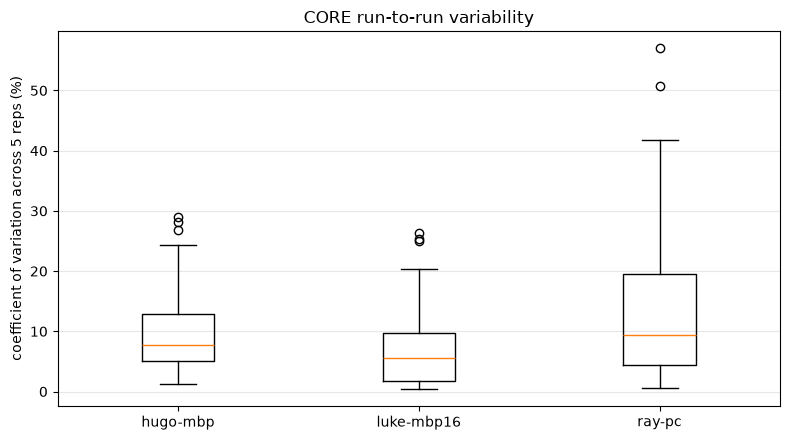

In [15]:
cv = (core.groupby(["code", "machine_id", "index_type", "workload"]).us_per_op
          .agg(lambda x: x.std() / x.mean()).rename("cv").reset_index())
display(cv.pivot_table(index="machine_id", columns="code", values="cv", aggfunc=["median", "max"]).round(3))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([cv[cv.machine_id == m].cv * 100 for m in mach], tick_labels=mach)
ax.set(ylabel="coefficient of variation across 5 reps (%)", title="CORE run-to-run variability")
ax.grid(True, axis="y", alpha=0.3)
save(fig, "partE_cv.png")

**Answer (Q4).** Median coefficient of variation: luke-mbp16 ≈5–6%, hugo-mbp ≈8%. ray-pc was 4.5% in its
original-code session but 18.4% (max 57%) in its fixed-code session. The same machine was the quietest
in one session and the noisiest in the other, so the noise came from that session (other programs
running, or power/heat throttling), not the hardware. Ray should rerun the fixed-code CORE suite with
the laptop plugged in and other apps closed.

### Q5. RAM needed per index, and could RAM differences matter?

In [16]:
per_key = mem.iloc[-1] * 1e6 / mem.index[-1]
vm = core.groupby("machine_id").mem_total_gb.first()
t = pd.DataFrame({"MB at 114k": mem.iloc[-1].round(1), "bytes per key": per_key.round(0)})
for m, gb in vm.items():
    t[f"millions of keys to fill {m} ({gb} GB)"] = (gb * 1e9 / per_key / 1e6).round(0)
display(t)

,MB at 114k,bytes per key,millions of keys to fill hugo-mbp (7.65 GB),millions of keys to fill luke-mbp16 (7.75 GB),millions of keys to fill ray-pc (15.47 GB)
index_type,,,,,
unsorted_list,7.4,65.0,118.0,119.0,238.0
sorted_list,8.3,73.0,105.0,107.0,213.0
hash_table,22.3,195.0,39.0,40.0,79.0
avl_tree,13.1,115.0,66.0,67.0,134.0
bplus_tree,9.2,80.0,95.0,97.0,193.0
ref_dict,10.5,92.0,83.0,84.0,168.0
ref_bisect,8.3,73.0,105.0,107.0,213.0


**Answer (Q5).** At 114k keys the indexes need 7.4 MB (unsorted list) to 22.3 MB (hash table, 195 bytes
per key). The Docker VMs have 7.65 GB, 7.75 GB and 15.47 GB, so RAM differences cannot affect these
results. Even the hash table would need roughly 39 million keys to fill a Mac's VM and 79 million to
fill ray-pc's. In practice the limit comes sooner, because these figures leave out the keys themselves
and the loaded dataset.